# AgentTasks: first exploratory analysis

One row is an observed agent assignment on a repository. The published table is **`agent_tasks`** (plural), not `agent_task`.

Run cells from top to bottom with the **AgentLogs EDA (Python 3.12)** kernel, or select `eda\.venv\Scripts\python.exe`. No new packages are needed.

The default downloads only the task table (about 83.7 MB) and `VERSION` from Hugging Face, not session logs or other tables. Downloads are cached under the repository's Git-ignored data directory. A deliberately selected sample mode is available for offline practice; there is no silent fallback.

Sources: [dataset card](https://huggingface.co/datasets/risenlab/agentlogs), [pinned release](https://huggingface.co/datasets/risenlab/agentlogs/tree/1.0-20261008), [task schema](../docs/schema/agent_task.md), and [research feasibility v2](../esgcidba/research_oppotunities_v2.md).

Goals: understand fields and nesting, assess missingness and identifiers, examine task states and timing, inspect session/artifact links, and identify limits on subsequent research.

In [10]:
from pathlib import Path
from importlib.metadata import version
import sys

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq
import seaborn as sns
from huggingface_hub import HfApi, snapshot_download
from agentlogs.schema import assert_dataset_version
from IPython.display import display

roots = [p for p in [Path.cwd(), *Path.cwd().parents]
         if (p / 'packages' / 'risenlab-agentlogs').is_dir()
         and (p / 'data' / 'dataset-sample').is_dir()]
if not roots:
    raise FileNotFoundError('Open this notebook from within the agentlogs repository.')
REPO_ROOT = roots[0]
DATA_SOURCE = 'huggingface'  # Set explicitly to 'sample' for offline practice.
DATASET_ID = 'risenlab/agentlogs'
RELEASE = '1.0-20261008'
REVISION = '25549ec57745fdf174620c1e75d7fd02d9c4dc22'
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)
print('Interpreter:', sys.executable)
display(pd.Series({p: version(p) for p in
    ['risenlab-agentlogs', 'huggingface-hub', 'duckdb', 'pandas', 'pyarrow']}, name='version'))

Interpreter: c:\Users\clwong\Documents\ESGCIDBA\agentlogs\eda\.venv\Scripts\python.exe


risenlab-agentlogs     1.0.1
huggingface-hub        2.2.0
duckdb                 2.0.0
pandas                 3.0.6
pyarrow               26.0.0
Name: version, dtype: str

## 1. Acquire only the task table and record provenance

The immutable commit was resolved from release `1.0-20261008`. Inspect the remote shard inventory and byte count before acquisition. The allowlist contains exact paths, preventing an accidental full-dataset download. Hugging Face errors are allowed to surface; an unavailable remote source is not replaced with sample data.

The published release cutoff is 30 September 2026. It is not the download date or necessarily the creation date of every task.

In [11]:
if DATA_SOURCE == 'huggingface':
    info = HfApi().dataset_info(DATASET_ID, revision=REVISION, files_metadata=True)
    if info.sha != REVISION:
        raise ValueError(f'Unexpected dataset revision: {info.sha}')
    shards = [s for s in info.siblings
              if s.rfilename.startswith('agent_tasks/') and s.rfilename.endswith('.parquet')]
    if not shards:
        raise FileNotFoundError('No agent_tasks Parquet shards in the pinned revision.')
    inventory = pd.DataFrame({'file': [s.rfilename for s in shards],
                              'bytes': [s.size for s in shards]})
    display(inventory)
    print('Task download size (decimal MB):', inventory['bytes'].sum() / 1_000_000)
    dataset_path = Path(snapshot_download(
        repo_id=DATASET_ID, repo_type='dataset', revision=REVISION,
        allow_patterns=['VERSION', *inventory['file'].tolist()],
        local_dir=REPO_ROOT / 'data' / 'eda' / RELEASE / REVISION,
    ))
    parquet_files = [dataset_path / name for name in inventory['file']]
elif DATA_SOURCE == 'sample':
    dataset_path = REPO_ROOT / 'data' / 'dataset-sample'
    parquet_files = sorted((dataset_path / 'agent_tasks').glob('*.parquet'))
    print('DEMONSTRATION SAMPLE ONLY: not representative of the full release.')
else:
    raise ValueError("DATA_SOURCE must be 'huggingface' or 'sample'.")

assert_dataset_version(dataset_path)
if not parquet_files or not all(p.is_file() for p in parquet_files):
    raise FileNotFoundError('Expected task shards are missing.')
provenance = pd.Series({
    'source': DATA_SOURCE, 'dataset': DATASET_ID, 'release': RELEASE,
    'revision': REVISION if DATA_SOURCE == 'huggingface' else 'local bundled sample',
    'schema_marker': (dataset_path / 'VERSION').read_text().strip(),
    'retrieved_or_opened_utc': pd.Timestamp.now(tz='UTC').isoformat(),
    'shards': len(parquet_files), 'local_path': str(dataset_path),
}, name='provenance')
display(provenance)

,file,bytes
0,agent_tasks/part_00000_of_00001.parquet,83682890


Task download size (decimal MB): 83.68289


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

source                                                           huggingface
dataset                                                   risenlab/agentlogs
release                                                         1.0-20261008
revision                            25549ec57745fdf174620c1e75d7fd02d9c4dc22
schema_marker                                                   1.0-20261008
retrieved_or_opened_utc                     2026-10-26T08:09:25.176604+00:00
shards                                                                     1
local_path                 C:\Users\clwong\Documents\ESGCIDBA\agentlogs\d...
Name: provenance, dtype: object

## 2. Inspect schema before flattening

`repository`, `creator`, and `custom_agent` are structs. `sessions`, `pull_request_artifacts`, `branch_artifacts`, and `agent_collaborators` are lists of structs. A missing list is unknown; an empty list means no references recorded. Neither guarantees the real-world absence of activity.

We retain one row per task. Exploding several lists at once would multiply rows and distort counts. Only a compact projection is loaded into pandas; the nested source remains queryable in DuckDB.

In [12]:
print(pq.read_schema(parquet_files[0]))
display(pd.DataFrame([{'shard': p.name, 'rows': pq.read_metadata(p).num_rows,
                       'bytes': p.stat().st_size} for p in parquet_files]))
con = duckdb.connect(database=':memory:')
con.read_parquet([str(p) for p in parquet_files]).create_view('agent_tasks', replace=True)
display(con.sql('DESCRIBE agent_tasks').df())
missing_records = []
for column in con.sql('DESCRIBE agent_tasks').df()['column_name']:
    quoted = '"' + column.replace('"', '""') + '"'
    missing_records.append({'field': column, 'null_count': con.sql(
        f'SELECT count(*) - count({quoted}) FROM agent_tasks').fetchall()[0][0]})
source_rows = con.sql('SELECT count(*) FROM agent_tasks').fetchall()[0][0]
if source_rows == 0:
    raise ValueError('The task table is empty.')
missingness = pd.DataFrame(missing_records)
missingness['null_pct'] = 100 * missingness['null_count'] / source_rows
display(missingness.sort_values('null_pct', ascending=False))

id: string not null
repository: struct<full_name: string not null> not null
  child 0, full_name: string not null
sessions: list<element: struct<id: string not null, session_index: int64 not null>> not null
  child 0, element: struct<id: string not null, session_index: int64 not null>
      child 0, id: string not null
      child 1, session_index: int64 not null
creator: struct<id: int64, login: string, graphql_id: string, type: string> not null
  child 0, id: int64
  child 1, login: string
  child 2, graphql_id: string
  child 3, type: string
pull_request_artifacts: list<element: struct<id: int64, graphql_id: string, number: int64, repository: struct<full_name: str (... 15 chars omitted) not null
  child 0, element: struct<id: int64, graphql_id: string, number: int64, repository: struct<full_name: string not null>>
      child 0, id: int64
      child 1, graphql_id: string
      child 2, number: int64
      child 3, repository: struct<full_name: string not null>
          child 0, fu

,shard,rows,bytes
0,part_00000_of_00001.parquet,363624,83682890


,column_name,column_type,null,key,default,extra
0,id,VARCHAR,YES,None,None,None
1,repository,STRUCT(full_name VARCHAR),YES,None,None,None
2,sessions,"STRUCT(id VARCHAR, session_index BIGINT)[]",YES,None,None,None
3,creator,"STRUCT(id BIGINT, login VARCHAR, graphql_id VA...",YES,None,None,None
4,pull_request_artifacts,"STRUCT(id BIGINT, graphql_id VARCHAR, number B...",YES,None,None,None
5,name,VARCHAR,YES,None,None,None
6,state,VARCHAR,YES,None,None,None
7,archived,BOOLEAN,YES,None,None,None
8,remote_steerable,BOOLEAN,YES,None,None,None
9,sharing_status,VARCHAR,YES,None,None,None


,field,null_count,null_pct
14,automation_id,363621,99.999175
13,custom_agent,360024,99.009966
12,archived_at,137962,37.940840
5,name,1052,0.289310
0,id,0,0.000000
4,pull_request_artifacts,0,0.000000
1,repository,0,0.000000
3,creator,0,0.000000
2,sessions,0,0.000000
8,remote_steerable,0,0.000000


In [13]:
tasks = con.sql('''
    SELECT id, repository.full_name AS repository_name,
           creator.type AS creator_type, creator.id AS creator_id,
           state, sharing_status, archived, remote_steerable,
           created_at, updated_at, archived_at,
           length(sessions) AS session_count,
           length(pull_request_artifacts) AS pr_reference_count,
           length(branch_artifacts) AS branch_reference_count,
           length(agent_collaborators) AS collaborator_count,
           custom_agent.name AS custom_agent_name,
           custom_agent.is_automation AS custom_agent_is_automation,
           automation_id IS NOT NULL AS has_automation_id,
           length(name) AS task_name_characters
    FROM agent_tasks
''').df()
for column in ['created_at', 'updated_at', 'archived_at']:
    tasks[column] = pd.to_datetime(tasks[column], utc=True, errors='raise')
tasks['update_lag_hours'] = (tasks['updated_at'] - tasks['created_at']).dt.total_seconds() / 3600
assert len(tasks) == source_rows, 'Flattening changed the task denominator.'
display(tasks.head())
print(f'Projected frame: {len(tasks):,} rows; {tasks.memory_usage(deep=True).sum() / 1_000_000:.1f} MB')
print('Raw task names are not displayed by default to minimize identifiable request text.')

,id,repository_name,creator_type,creator_id,state,sharing_status,archived,remote_steerable,created_at,updated_at,archived_at,session_count,pr_reference_count,branch_reference_count,collaborator_count,custom_agent_name,custom_agent_is_automation,has_automation_id,task_name_characters,update_lag_hours
0,5e4ddd39-66f7-4053-9dfb-b21b545b8d58,connectbot/connectbot,user,50407,completed,unshared,True,True,2025-11-17 02:22:34.181000+00:00,2025-11-17 02:26:35.473000+00:00,2025-11-17 02:26:35.473000+00:00,1,1,0,1,NaN,<NA>,False,45,0.067026
1,fa6015e0-e150-4898-a3a3-c3627b5326e3,connectbot/connectbot,user,50407,cancelled,unshared,True,True,2025-11-26 17:58:20.824000+00:00,2025-11-26 18:16:19.460000+00:00,2025-11-26 18:16:19.460000+00:00,2,1,0,1,NaN,<NA>,False,53,0.299621
2,914ce158-dbee-4946-97f2-328a694615c0,connectbot/connectbot,user,50407,completed,unshared,True,True,2026-05-06 14:59:27.796000+00:00,2026-05-06 17:57:44.213000+00:00,2026-05-06 17:57:44.213000+00:00,1,1,1,1,NaN,<NA>,False,56,2.971227
3,f1d385f0-ff95-406b-b6a4-cb0bc0ce16de,connectbot/connectbot,user,50407,completed,unshared,True,False,2025-12-08 14:08:17.389000+00:00,2026-09-24 20:08:02.262000+00:00,2026-09-24 20:08:02.262000+00:00,1,1,0,1,NaN,<NA>,False,22,6965.995798
4,ed2d191a-4091-40aa-bfe2-ccec96b64fee,connectbot/connectbot,user,50407,completed,unshared,True,True,2026-09-24 20:08:29.603000+00:00,2026-09-24 20:40:41.426000+00:00,2026-09-24 20:40:41.426000+00:00,1,1,1,1,NaN,<NA>,False,46,0.536618


Projected frame: 363,624 rows; 77.2 MB
Raw task names are not displayed by default to minimize identifiable request text.


## 3. Check identifiers, missingness, and timestamps

These checks report issues without dropping or silently repairing rows. `updated_at - created_at` is a metadata update lag, **not execution time, labor time, or resolution lead time**. A task may be updated long after execution.

Missing values inside structs can exist even when the parent struct is present. The flattened missingness table complements the top-level audit.

In [14]:
quality = pd.Series({
    'task_rows': len(tasks), 'distinct_task_ids': tasks['id'].nunique(),
    'null_task_ids': tasks['id'].isna().sum(),
    'duplicate_id_rows_after_first': tasks['id'].duplicated().sum(),
    'distinct_repositories': tasks['repository_name'].nunique(),
    'missing_repository': tasks['repository_name'].isna().sum(),
    'missing_creation_timestamp': tasks['created_at'].isna().sum(),
    'updated_before_created': tasks['update_lag_hours'].lt(0).sum(),
    'archived_before_created': tasks['archived_at'].lt(tasks['created_at']).sum(),
}, name='value')
display(quality)
display(pd.DataFrame({'null_count': tasks.isna().sum(),
                      'null_pct': tasks.isna().mean().mul(100)}).sort_values('null_pct', ascending=False))
display(tasks[['created_at', 'updated_at', 'archived_at']].agg(['min', 'max']))
display(tasks[['session_count', 'pr_reference_count', 'branch_reference_count',
               'collaborator_count', 'task_name_characters', 'update_lag_hours']]
        .describe(percentiles=[0.5, 0.9, 0.95, 0.99]).T)
if DATA_SOURCE == 'huggingface':
    print(f'Published release count: 363,624 tasks; observed: {len(tasks):,}.')
    if len(tasks) != 363_624:
        print('ATTENTION: investigate the difference before interpreting release-wide summaries.')

task_rows                        363624
distinct_task_ids                363624
null_task_ids                         0
duplicate_id_rows_after_first         0
distinct_repositories             40565
missing_repository                    0
missing_creation_timestamp            0
updated_before_created               52
archived_before_created             458
Name: value, dtype: int64

,null_count,null_pct
custom_agent_name,360422,99.119420
custom_agent_is_automation,360024,99.009966
archived_at,137962,37.940840
task_name_characters,1052,0.289310
creator_type,351,0.096528
creator_id,0,0.000000
id,0,0.000000
repository_name,0,0.000000
remote_steerable,0,0.000000
state,0,0.000000


,created_at,updated_at,archived_at
min,2025-05-11 16:00:40.625000+00:00,2025-05-11 16:11:03.351000+00:00,2025-01-07 14:42:46+00:00
max,2026-09-29 18:25:25.953000+00:00,2026-09-29 19:05:21.952000+00:00,2026-09-29 18:26:50.724000+00:00


,count,mean,std,min,50%,90%,95%,99%,max
session_count,363624.0,1.748746,2.321351,0.0,1.0,3.0,5.0,11.0,194.0
pr_reference_count,363624.0,0.94966,0.248195,0.0,1.0,1.0,1.0,1.0,15.0
branch_reference_count,363624.0,0.611712,0.487361,0.0,1.0,1.0,1.0,1.0,1.0
collaborator_count,363624.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0
task_name_characters,362572.0,52.546876,51.453793,1.0,49.0,67.0,76.0,110.0,1024.0
update_lag_hours,363624.0,114.415069,635.04489,-1008.43063,0.244555,47.366365,327.051257,3461.013084,11616.570007


Published release count: 363,624 tasks; observed: 363,624.


## 4. Task states and operational flags

Enumerate the actual state vocabulary instead of assuming session-state labels apply to tasks. A task state is not PR acceptance or verified engineering success. Percentages below use all task rows, including an explicit missing category.

,tasks,percent
state,,
completed,324951,89.364563
cancelled,21151,5.816723
failed,15264,4.197743
timed_out,1221,0.335786
queued,697,0.191682
in_progress,262,0.072052
waiting_for_user,78,0.021451


creator_type


,tasks,percent
creator_type,,
user,363273,99.903472
<missing>,351,0.096528


sharing_status


,tasks,percent
sharing_status,,
unshared,363624,100.0


...

,tasks,percent
remote_steerable,,
True,327370,90.029811
False,36254,9.970189


has_automation_id


,tasks,percent
has_automation_id,,
False,363621,99.999175
True,3,0.000825


custom_agent_is_automation


,tasks,percent
custom_agent_is_automation,,
<missing>,360024,99.009966
False,3202,0.88058
True,398,0.109454


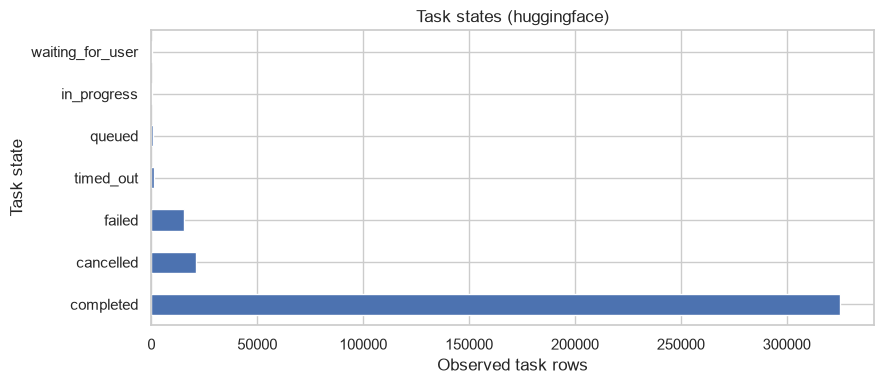

In [15]:
def frequency(series: pd.Series) -> pd.DataFrame:
    counts = series.astype('string').fillna('<missing>').value_counts(dropna=False)
    return pd.DataFrame({'tasks': counts, 'percent': counts / len(series) * 100})

state_summary = frequency(tasks['state'])
display(state_summary)
for column in ['creator_type', 'sharing_status', 'archived', 'remote_steerable',
               'has_automation_id', 'custom_agent_is_automation']:
    print(column)
    display(frequency(tasks[column]))
fig, ax = plt.subplots(figsize=(9, 4))
state_summary['tasks'].plot.barh(ax=ax)
ax.set(xlabel='Observed task rows', ylabel='Task state', title=f'Task states ({DATA_SOURCE})')
fig.tight_layout()
plt.show()

## 5. Sessions and artifacts recorded on tasks

Session references indicate recorded executions, not their outcomes or log completeness. Multiple references are not automatically retries or failures. PR references indicate work on a PR, not necessarily agent authorship or a merge. Branch and collaborator links have similarly limited semantics.

The reference audit counts missing IDs, repeats within a task, and IDs linked across tasks. It does **not** check whether the target rows exist, because no other tables are downloaded.

In [16]:
link_columns = ['session_count', 'pr_reference_count', 'branch_reference_count', 'collaborator_count']
link_summary = pd.DataFrame({
    column: {'unknown_list': tasks[column].isna().sum(),
             'empty_list': tasks[column].eq(0).sum(),
             'one_reference': tasks[column].eq(1).sum(),
             'multiple_references': tasks[column].gt(1).sum()}
    for column in link_columns
}).T
display(link_summary)
display(pd.crosstab(tasks['state'].astype('string').fillna('<missing>'),
    tasks['session_count'].map(lambda n: 'unknown' if pd.isna(n) else '0' if n == 0 else '1' if n == 1 else '2+'),
    margins=True))
display(con.sql('''
    WITH refs AS (
        SELECT id AS task_id, unnest(sessions) AS session FROM agent_tasks
    )
    SELECT count(*) AS reference_rows, count(session.id) AS references_with_id,
           count(DISTINCT session.id) AS distinct_session_ids,
           count(*) - count(DISTINCT (task_id, session.id)) AS repeated_task_session_pairs
    FROM refs
''').df())
display(con.sql('''
    WITH refs AS (SELECT id AS task_id, unnest(sessions) AS session FROM agent_tasks),
    shared AS (SELECT session.id FROM refs WHERE session.id IS NOT NULL
               GROUP BY session.id HAVING count(DISTINCT task_id) > 1)
    SELECT count(*) AS session_ids_referenced_by_multiple_tasks FROM shared
''').df())
print('Session/PR target-table existence and outcome joins are deferred to later notebooks.')

,unknown_list,empty_list,one_reference,multiple_references
session_count,0,10192,246849,106583
pr_reference_count,0,20599,340785,2240
branch_reference_count,0,141191,222433,0
collaborator_count,0,0,363624,0


session_count,0,1,2+,All
state,,,,
cancelled,111,16850,4190,21151
completed,6889,219794,98268,324951
failed,2828,8883,3553,15264
in_progress,4,189,69,262
queued,349,290,58,697
timed_out,11,793,417,1221
waiting_for_user,0,50,28,78
All,10192,246849,106583,363624


,reference_rows,references_with_id,distinct_session_ids,repeated_task_session_pairs
0,635886,635886,635886,0


,session_ids_referenced_by_multiple_tasks
0,0


Session/PR target-table existence and outcome joins are deferred to later notebooks.


## 6. Activity over time and repository concentration

These are task creation counts in the observed snapshot, not adoption rates, productivity, or the number of active firms. Boundary months may be incomplete. Repository concentration affects sampling and clustered inference; a public repository is not necessarily an enterprise team.

,tasks
created_at,
2025-05-01 00:00:00+00:00,1231
2025-06-01 00:00:00+00:00,2910
2025-07-01 00:00:00+00:00,5609
2025-08-01 00:00:00+00:00,9147
2025-09-01 00:00:00+00:00,9921
2025-10-01 00:00:00+00:00,14395
2025-11-01 00:00:00+00:00,30709
2025-12-01 00:00:00+00:00,46386
2026-01-01 00:00:00+00:00,23805


,tasks
repository_name,
github/gh-aw,14466
microsoft/vscode,3085
dotnet/runtime,2553
github/gh-aw-firewall,1889
github/gh-aw-mcpg,1872
musicmonk42/the_code_factory_working_v2,1785
mlflow/mlflow,1500
epam/ketcher,1463
camunda/camunda,1344


top_repository_share_pct                3.978285
top_10_repository_share_pct             8.558016
median_tasks_per_observed_repository    2.000000
tasks_with_missing_repository           0.000000
Name: value, dtype: float64

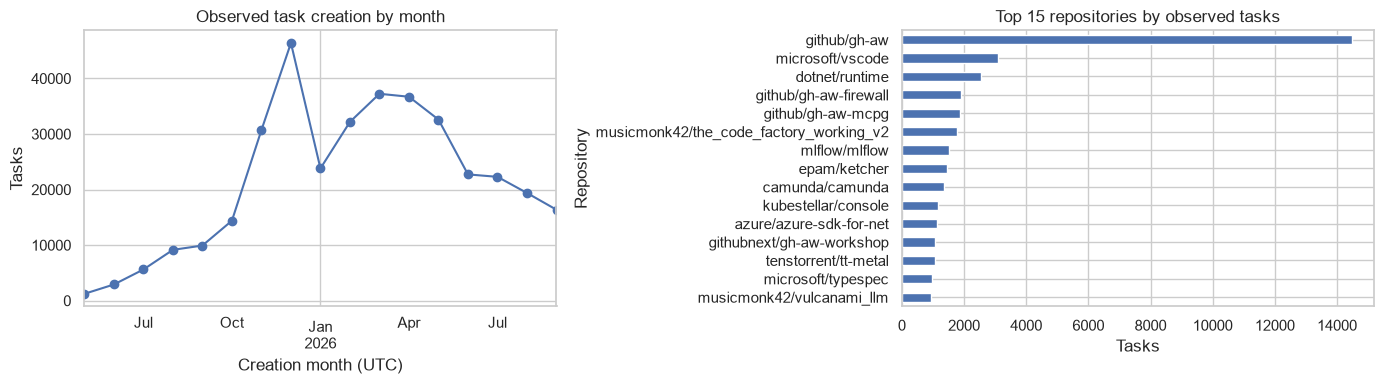

In [17]:
monthly = tasks.set_index('created_at').resample('MS').size().rename('tasks')
display(monthly.to_frame())
repo_counts = tasks['repository_name'].dropna().value_counts()
display(repo_counts.head(15).rename('tasks').to_frame())
display(pd.Series({
    'top_repository_share_pct': repo_counts.head(1).sum() / len(tasks) * 100,
    'top_10_repository_share_pct': repo_counts.head(10).sum() / len(tasks) * 100,
    'median_tasks_per_observed_repository': repo_counts.median(),
    'tasks_with_missing_repository': tasks['repository_name'].isna().sum(),
}, name='value'))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
monthly.plot(ax=axes[0], marker='o')
axes[0].set(title='Observed task creation by month', xlabel='Creation month (UTC)', ylabel='Tasks')
repo_counts.head(15).sort_values().plot.barh(ax=axes[1])
axes[1].set(title='Top 15 repositories by observed tasks', xlabel='Tasks', ylabel='Repository')
fig.tight_layout()
plt.show()

In [22]:
repo_monthly_counts = (
    tasks.loc[tasks['repository_name'].isin(repo_counts.head(15).index)]
    .groupby(['repository_name', pd.Grouper(key='created_at', freq='MS')])
    .size()
    .unstack(fill_value=0)
    .reindex(index=repo_counts.head(15).index, columns=monthly.index, fill_value=0)
)
repo_monthly_counts.columns = repo_monthly_counts.columns.strftime('%Y-%m')

repo_monthly_summary = repo_monthly_counts.assign(
    min=repo_monthly_counts.min(axis=1),
    max=repo_monthly_counts.max(axis=1),
    mean=repo_monthly_counts.mean(axis=1),
    median=repo_monthly_counts.median(axis=1),
    std=repo_monthly_counts.std(axis=1),
    coef_var=repo_monthly_counts.std(axis=1) / repo_monthly_counts.mean(axis=1),
    months_with_tasks=repo_monthly_counts.gt(0).sum(axis=1),
    total_tasks=repo_monthly_counts.sum(axis=1),
).reset_index()

display(repo_monthly_summary.round({'mean': 2, 'std': 2}))

created_at,repository_name,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,min,max,mean,median,std,coef_var,months_with_tasks,total_tasks
0,github/gh-aw,0,0,0,0,0,0,38,11,0,1456,1187,1575,1921,2170,2381,2645,1082,0,2645,850.94,38.0,998.01,1.172833,10,14466
1,microsoft/vscode,9,114,117,152,138,106,304,548,289,228,181,136,145,91,183,217,127,9,548,181.47,145.0,118.80,0.654642,17,3085
2,dotnet/runtime,21,14,21,36,18,86,116,221,182,211,250,264,239,237,261,225,151,14,264,150.18,182.0,98.00,0.652575,17,2553
3,github/gh-aw-firewall,0,0,0,0,0,0,5,4,0,160,68,124,367,413,282,195,271,0,413,111.12,5.0,144.05,1.296337,10,1889
4,github/gh-aw-mcpg,0,0,0,0,0,0,0,0,0,161,151,168,220,603,272,127,170,0,603,110.12,0.0,158.47,1.439140,8,1872
5,musicmonk42/the_code_factory_working_v2,0,0,0,0,0,0,188,36,363,1038,160,0,0,0,0,0,0,0,1038,105.00,0.0,260.29,2.478968,5,1785
6,mlflow/mlflow,28,37,18,51,158,115,92,123,140,163,180,154,19,7,4,28,183,4,183,88.24,92.0,66.84,0.757571,17,1500
7,epam/ketcher,0,0,0,0,0,137,209,72,50,55,61,29,45,36,104,429,236,0,429,86.06,50.0,113.38,1.317505,12,1463
8,camunda/camunda,0,4,17,5,19,6,100,224,70,121,175,199,164,92,67,46,35,0,224,79.06,67.0,74.00,0.935953,16,1344
9,kubestellar/console,0,0,0,0,0,0,0,0,39,223,374,320,0,206,0,0,0,0,374,68.35,0.0,126.62,1.852494,5,1162


## 7. Get the counts and percentage contribution of each task (name column)

In [18]:
# Group exact task names, retaining missing names in the denominator.
task_name_summary = con.sql('''
    SELECT name,
           count(*) AS task_count,
           100.0 * count(*) / sum(count(*)) OVER () AS percent
    FROM agent_tasks
    GROUP BY name
    ORDER BY task_count DESC, name NULLS LAST
''').df()

display(task_name_summary)

,name,task_count,percent
0,Reviewing pull request,35347,9.720756
1,Analyzing and fixing GitHub Actions job failure,4650,1.278793
2,New task,2861,0.786802
3,NaN,1052,0.289310
4,Initial implementation,588,0.161705
...,...,...,...
297082,🧬 Implement Darwin Gödel Machine (DGM) evoluti...,1,0.000275
297083,🧹 Clean up unnecessary console logs and unused...,1,0.000275
297084,🧹 Implement Central Package Management (CPM) f...,1,0.000275
297085,🧹 Resolve Linting Issues Using `make lint` - 9...,1,0.000275


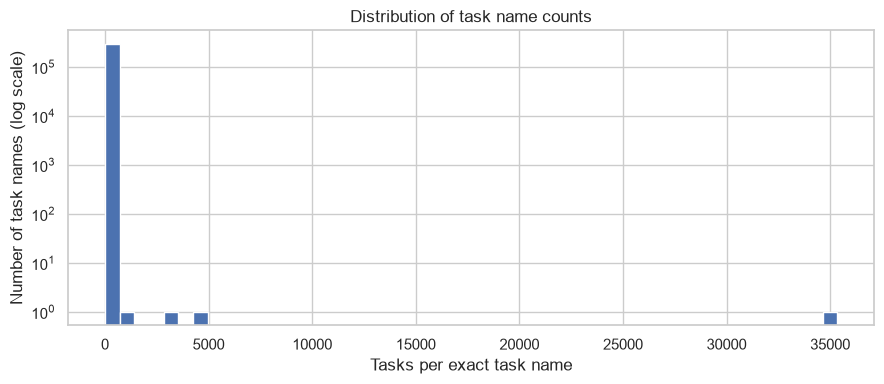

In [19]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(task_name_summary['task_count'].dropna(), bins=50)
ax.set(
    xlabel='Tasks per exact task name',
    ylabel='Number of task names (log scale)',
    title='Distribution of task name counts',
    yscale='log',
)
fig.tight_layout()
plt.show()

## 8. Record observations before selecting an RQ

After reviewing the outputs, record:

* Which state values actually occur, and whether their meanings need clarification
* The fraction of tasks with zero, one, multiple, or unknown session/PR references
* Missingness in optional metadata and timestamps, and any duplicate identifiers
* Repository concentration and whether a few repositories dominate the snapshot
* Date coverage and possible collection or boundary effects

Do not convert these descriptions into hypothesis tests yet. This table does not contain original human prompt text, model choices, tokens, validated costs, execution outcomes, or PR merge timestamps. Those require careful joins to sessions, logs, and PRs. Task names are not a substitute for original prompts.

For the [v2 research questions](../esgcidba/research_oppotunities_v2.md), this notebook establishes the task denominator and linkage starting point only. Next steps are a session-table EDA and join-coverage audit, before any model/cost comparison.

The full release is observational public-platform data, not a random sample of all software work. The bundled sample mode is for practice only. Neither establishes causality or enterprise ROI.

Attribution: AgentLogs dataset by RISEN Lab, licensed under CC BY 4.0. [Dataset paper](https://doi.org/10.48550/arXiv.2608.29204).